# EXP-DENSENET121-TRANSFER-5SEEDS-014

Five-seed DenseNet121 **ImageNet transfer learning** on the frozen
`CashewData_Split (8).zip` (`Cashew_dataV08_real_val`). This is an independent
experiment: no EXP-013 weights or results are reused. Stage 1 trains a new
classification head with a frozen ImageNet backbone. Stage 2 restores the
best Stage 1 weights and fine-tunes only `conv5_*` non-BatchNorm layers and
the head. Validation loss selects the stage checkpoint and deployment seed.

The setup and input augmentation follow the EXP-013 source notebook.
Differences are ImageNet initialization, two stage learning rates, partial
backbone fine-tuning and frozen BatchNorm statistics. They are a **method
comparison**, not an ablation of pretrained weights alone. Existing EXP-013
Test and historical real holdout results must not tune EXP-014.

Default flags train five seeds after a pipeline smoke check. Final Test and
real holdout are **off** until a separate evaluation run after the Validation
selection lock exists. The 48-image historical holdout is previously exposed;
any eventual result from it is descriptive, not a new blind field estimate.

**Status on creation:** implementation prepared; training and metrics PENDING.


In [ ]:
import sys
print("Python:", sys.executable)

!nvidia-smi

Python: /usr/bin/python3
Mon Oct 19 08:13:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   33C    P0             48W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+----------------------

In [ ]:

# ============================================================
# 01. IMPORT LIBRARIES
# ============================================================

import os
import sys
import io
import gc
import json
import time
import random
import shutil
import platform
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)

from IPython.display import display
import ipywidgets as widgets

MATRIX_CMAP = LinearSegmentedColormap.from_list(
    "readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)

plt.rcParams.update({
    "text.color": "black", "axes.labelcolor": "black",
    "axes.titlecolor": "black", "xtick.color": "black", "ytick.color": "black",
})

print("Imports completed.")


Imports completed.


In [ ]:

# ============================================================
# 02. ENVIRONMENT INFORMATION
# ============================================================

print(f"Date              : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python            : {sys.version.split()[0]}")
print(f"TensorFlow        : {tf.__version__}")
print(f"Keras             : {keras.__version__ if hasattr(keras, '__version__') else 'tf.keras'}")
RUNTIME = ("Windows" if os.name == "nt" else "Kaggle" if Path("/kaggle/working").is_dir() else "Colab" if Path("/content").is_dir() else platform.system())
print(f"Runtime           : {RUNTIME}")
print(f"OS                : {platform.platform()}")

gpus = tf.config.list_physical_devices("GPU")
print(f"GPU Count         : {len(gpus)}")
if RUNTIME == "Colab" and not gpus:
    raise RuntimeError("Colab has no GPU. Select a GPU runtime and rerun from the first cell.")

for i, gpu in enumerate(gpus):
    print(f"GPU {i}             : {gpu}")

if gpus:
    strategy = tf.distribute.OneDeviceStrategy(device="/GPU:0")
else:
    strategy = tf.distribute.OneDeviceStrategy(device="/CPU:0")

print(f"Strategy          : {strategy.__class__.__name__}")
print(f"Replicas          : {strategy.num_replicas_in_sync}")


Date              : 2026-10-19 08:13:51
Python            : 3.13.15
TensorFlow        : 2.21.0
Keras             : 3.13.2
Runtime           : Colab
OS                : Linux-6.6.122+-x86_64-with-glibc2.39
GPU Count         : 1
GPU 0             : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Strategy          : OneDeviceStrategy
Replicas          : 1


In [ ]:

# ============================================================
# 03. CONFIGURATION — EXP-014
# ============================================================

NOTEBOOK_VERSION = "014"
NOTEBOOK_SOURCE_PATH = None  # Optional path to this exact 014 .ipynb on Drive.
EXPERIMENT_ID = "EXP-DENSENET121-TRANSFER-5SEEDS-014"
DATASET_VERSION = "Cashew_dataV08_real_val"
DATASET_ARCHIVE_NAME = "CashewData_Split (8).zip"
DATASET_ARCHIVE_FILE_ID = None  # Mounted Drive path is authoritative on Colab.
DATASET_ARCHIVE_OVERRIDE = None  # Optional exact ZIP path, useful on Kaggle.


DRIVE_TARGET_URL = (
    "https://drive.google.com/drive/folders/"
    "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing"
)
DRIVE_TARGET_FOLDER_ID = "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti"

EXPECTED_CLASSES = [
    "anthracnose",
    "healthy",
    "leaf_miner",
    "red_rust",
    "not_cashew_leaf",
]

EXPECTED_COUNTS = {
    "anthracnose": {
        "train": 939,
        "val": 308,
        "test": 122,
        "total": 1369,
    },

    "healthy": {
        "train": 803,
        "val": 216,
        "test": 118,
        "total": 1137,
    },

    "leaf_miner": {
        "train": 875,
        "val": 264,
        "test": 132,
        "total": 1271,
    },

    "not_cashew_leaf": {
        "train": 1101,
        "val": 314,
        "test": 156,
        "total": 1571,
    },

    "red_rust": {
        "train": 1072,
        "val": 328,
        "test": 158,
        "total": 1558,
    },
}

EXPECTED_TOTALS = {
    "train": 4790,
    "val": 1430,
    "test": 686,
    "total": 6906,
}

STRICT_DATASET_CHECK = True
EXPECTED_REAL_FILENAME_COUNTS = {"train": 135, "val": 35, "test": 28}


# Removed files that must not appear in Split (8).
REQUIRED_ABSENT_IMAGES = [
    "val/leaf_miner/leaf_miner_1056.jpg",
    "val/leaf_miner/leaf_miner_1091.jpg",
    "test/not_cashew_leaf/not_cashew_leaf_1514.JPG",
]

# ------------------------------------------------------------
# Fixed five-seed, two-stage transfer protocol
# ------------------------------------------------------------
SEEDS = [42, 123, 2026, 3407, 7777]
IMG_SIZE = 224
BATCH_SIZE = 16
MODEL_NAME = "DenseNet121"
TRAINING_MODE = "ImageNet Transfer, two-stage"
PRETRAINED_WEIGHTS = "imagenet"
HEAD_DROPOUT = 0.40
WEIGHT_DECAY = 1e-4
STAGE1_LR, STAGE1_EPOCHS = 3e-4, 12
STAGE1_EARLY_PATIENCE, STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR = 4, 2, 1e-6
STAGE2_LR, STAGE2_EPOCHS = 1e-5, 30
STAGE2_EARLY_PATIENCE, STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR = 8, 4, 1e-7
LR_REDUCTION_FACTOR = 0.5
EXPECTED_MANIFEST_SHA256 = "1810d7e654fede9c8f6a9d08a4078be7882492db2d2d842a19b5320b9aae356b"

RUN_PIPELINE_SMOKE = True
RUN_FULL_TRAINING = True
RUN_FINAL_TEST = False
RUN_REAL_HOLDOUT = False  # Historical, already inspected 48-image set.
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout.zip"
REAL_HOLDOUT_ARCHIVE_SHA256 = "BDDCB61CA9AF6111E0B26DB7876D0A3309C587AEAFFAEF49B7A9D2D162309165"
REAL_HOLDOUT_EXPECTED_COUNTS = {"anthracnose": 13, "healthy": 5, "leaf_miner": 24, "red_rust": 7}
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None

if RUN_FULL_TRAINING and (RUN_FINAL_TEST or RUN_REAL_HOLDOUT):
    raise RuntimeError("Finish and lock all five Validation runs before enabling Test or holdout.")

# Separate result namespace; EXP-013 is never modified.
if RUNTIME == "Windows":
    PROJECT_ROOT = Path(r"D:\Study\KhoaLuanTotNghiep\Resource")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Kaggle":
    PROJECT_ROOT = Path("/kaggle/working")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content")
    DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/Cashew_Leaf_model_result")
    DRIVE_DATASET_ARCHIVE = DRIVE_PROJECT_DIR / "Dataset" / DATASET_ARCHIVE_NAME
    if not DRIVE_PROJECT_DIR.is_dir():
        raise FileNotFoundError(DRIVE_PROJECT_DIR)
    RESULTS_ROOT = DRIVE_PROJECT_DIR / "training_results" / "current_dataset"
else:
    raise RuntimeError(f"Unsupported runtime: {RUNTIME}")

OUT_DIR = RESULTS_ROOT / EXPERIMENT_ID
AGGREGATE_DIR = OUT_DIR / "aggregate"
PANEL_DIR = OUT_DIR / "figures" / "panels"
MODEL_PACKAGE_DIR = OUT_DIR / "model_package"
CODE_PACKAGE_DIR = OUT_DIR / "code"
ENV_DIR = OUT_DIR / "environment"
for directory in (OUT_DIR, AGGREGATE_DIR, PANEL_DIR, MODEL_PACKAGE_DIR, CODE_PACKAGE_DIR, ENV_DIR):
    directory.mkdir(parents=True, exist_ok=True)
if not RUN_FULL_TRAINING and not (OUT_DIR / "validation_selection_lock.json").is_file():
    raise FileNotFoundError("Evaluation requires a completed EXP-014 Validation lock.")
print("Experiment:", EXPERIMENT_ID)
print("Dataset:", DATASET_ARCHIVE_NAME, "| seeds:", SEEDS)
print("Flags:", RUN_FULL_TRAINING, RUN_FINAL_TEST, RUN_REAL_HOLDOUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Experiment: EXP-DENSENET121-TRANSFER-5SEEDS-014
Dataset: CashewData_Split (8).zip | seeds: [42, 123, 2026, 3407, 7777]
Flags: True False False


In [ ]:

# ============================================================
# 04. REPRODUCIBILITY
# ============================================================

def set_global_seed(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Đồng bộ Python / NumPy / TensorFlow theo Keras.
    try:
        keras.utils.set_random_seed(seed)
    except Exception:
        pass

    print(f"Global seed set to: {seed}")


try:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic operations: ENABLED")
except Exception as e:
    print("Deterministic operations: unavailable")
    print("Reason:", e)


Deterministic operations: ENABLED


In [ ]:
# ============================================================
# 05. LOAD FROZEN SPLIT (8) FROM THE EXACT ZIP
# ============================================================

EXPECTED_ZIP_SHA256 = "75c5928b2f6432aca901bc16831e91f9aa4bdacc1e2ff536753d71da60c147e7"

if DATASET_ARCHIVE_OVERRIDE is not None:
    archive_for_hash = Path(DATASET_ARCHIVE_OVERRIDE)
elif RUNTIME == "Windows":
    archive_for_hash = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / DATASET_ARCHIVE_NAME
elif RUNTIME == "Colab":
    archive_for_hash = DRIVE_DATASET_ARCHIVE
else:  # Kaggle input dataset should contain the original Split (8) ZIP.
    archive_candidates = sorted(Path("/kaggle/input").rglob(DATASET_ARCHIVE_NAME))
    if len(archive_candidates) != 1:
        raise RuntimeError(
            f"Expected one {DATASET_ARCHIVE_NAME} under /kaggle/input; "
            f"found: {archive_candidates}. Set DATASET_ARCHIVE_OVERRIDE if needed."
        )
    archive_for_hash = archive_candidates[0]

if not archive_for_hash.is_file():
    raise FileNotFoundError(
        f"Split (8) ZIP missing: {archive_for_hash}. "
        "Upload/mount the exact archive or set DATASET_ARCHIVE_OVERRIDE."
    )

digest = hashlib.sha256()
with archive_for_hash.open("rb") as stream:
    for block in iter(lambda: stream.read(8 << 20), b""):
        digest.update(block)
DATASET_ZIP_SHA256 = digest.hexdigest()
if DATASET_ZIP_SHA256 != EXPECTED_ZIP_SHA256:
    raise ValueError(
        f"Split (8) ZIP SHA256 mismatch: {DATASET_ZIP_SHA256}; "
        f"expected {EXPECTED_ZIP_SHA256}"
    )
print("Verified Split (8) ZIP:", archive_for_hash)
print("Dataset ZIP SHA256:", DATASET_ZIP_SHA256)

# Keep this cache separate from the Split (7) dataset used by version 011.
cache_parent = PROJECT_ROOT / "dataset_cache"
extraction_root = cache_parent / "split_08"
staging_root = cache_parent / "split_08_staging"
DATASET_PATH = extraction_root / "CashewData_Split"
marker = extraction_root / ".archive_sha256"

if extraction_root.exists():
    if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != EXPECTED_ZIP_SHA256:
        raise RuntimeError(
            f"Split (8) cache has no matching completion marker: {extraction_root}. "
            "Inspect it and remove or rename it before retrying."
        )
else:
    if staging_root.exists():
        raise RuntimeError(
            f"Previous Split (8) extraction is incomplete: {staging_root}. "
            "Inspect it and remove or rename it before retrying."
        )
    cache_parent.mkdir(parents=True, exist_ok=True)
    staging_root.mkdir()
    with zipfile.ZipFile(archive_for_hash) as dataset_archive:
        for member in dataset_archive.infolist():
            target = (staging_root / member.filename).resolve()
            if target != staging_root.resolve() and staging_root.resolve() not in target.parents:
                raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
            if not member.filename.startswith("CashewData_Split/"):
                raise ValueError(f"Unexpected Split (8) ZIP root: {member.filename}")
        print("Extracting Split (8) into:", staging_root)
        dataset_archive.extractall(staging_root)
    if not all((staging_root / "CashewData_Split" / name).is_dir()
               for name in ("train", "val", "test")):
        raise RuntimeError("Split (8) ZIP has no complete train/val/test directory tree.")
    (staging_root / ".archive_sha256").write_text(EXPECTED_ZIP_SHA256 + "\n", encoding="utf-8")
    staging_root.rename(extraction_root)

required_splits = [DATASET_PATH / name for name in ("train", "val", "test")]
missing_splits = [str(path) for path in required_splits if not path.is_dir()]
if missing_splits:
    raise FileNotFoundError(f"Split (8) cache is incomplete: {missing_splits}")

TRAIN_DIR = DATASET_PATH / "train"
VAL_DIR = DATASET_PATH / "val"
TEST_DIR = DATASET_PATH / "test"

unexpected_removed_files = [
    DATASET_PATH / Path(relative_path)
    for relative_path in REQUIRED_ABSENT_IMAGES
    if (DATASET_PATH / Path(relative_path)).is_file()
]
if unexpected_removed_files:
    raise ValueError(
        "Split (8) contains files that should be absent:\n" +
        "\n".join(str(path) for path in unexpected_removed_files)
    )

print("\nSelected dataset:", DATASET_PATH)
print("TRAIN_DIR:", TRAIN_DIR)
print("VAL_DIR  :", VAL_DIR)
print("TEST_DIR :", TEST_DIR)


Verified Split (8) ZIP: /content/drive/MyDrive/Cashew_Leaf_model_result/Dataset/CashewData_Split (8).zip
Dataset ZIP SHA256: 75c5928b2f6432aca901bc16831e91f9aa4bdacc1e2ff536753d71da60c147e7

Selected dataset: /content/dataset_cache/split_08/CashewData_Split
TRAIN_DIR: /content/dataset_cache/split_08/CashewData_Split/train
VAL_DIR  : /content/dataset_cache/split_08/CashewData_Split/val
TEST_DIR : /content/dataset_cache/split_08/CashewData_Split/test



# Dataset Audit

Notebook kiểm tra lại toàn bộ ảnh trước khi train.

Nếu:
- có ảnh decode lỗi;
- có file extension lạ;
- class folder sai;
- số lượng khác revision sạch trong `CashewData_Split (8).zip`;

thì notebook sẽ **dừng** khi `STRICT_DATASET_CHECK=True`.


In [ ]:

# ============================================================
# 06. DATASET AUDIT + EXACT COUNTS
# ============================================================

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"
}


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


from PIL import ImageOps
from scipy.fftpack import dct


def phash64(image):
    gray = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
    frequencies = dct(dct(gray, axis=0, norm="ortho"), axis=1, norm="ortho")[:8, :8]
    bits = frequencies > np.median(frequencies)
    return int("".join("1" if bit else "0" for bit in bits.flat), 2)


def pixel_hash(image):
    rgb = image.convert("RGB")
    digest = hashlib.sha256()
    digest.update(f"{rgb.width}x{rgb.height}:".encode())
    digest.update(rgb.tobytes())
    return digest.hexdigest()


def audit_split(split_name, split_dir):
    valid_rows = []
    bad_rows = []
    unknown_rows = []

    found_classes = sorted([
        p.name for p in split_dir.iterdir()
        if p.is_dir()
    ])

    if found_classes != sorted(EXPECTED_CLASSES):
        raise ValueError(
            f"Class folders của {split_name} không đúng.\n"
            f"Expected: {sorted(EXPECTED_CLASSES)}\n"
            f"Found   : {found_classes}"
        )

    for label, class_name in enumerate(EXPECTED_CLASSES):
        class_dir = split_dir / class_name

        for path in sorted(class_dir.rglob("*")):
            if not path.is_file():
                continue

            ext = path.suffix.lower()

            if ext not in VALID_EXTENSIONS:
                unknown_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "extension": ext,
                })
                continue

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    image = ImageOps.exif_transpose(img)
                    image.load()
                    pixels_sha = pixel_hash(image)
                    perceptual_hash = phash64(image)

                valid_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "label": label,
                    "path": str(path),
                    "relative_path": path.relative_to(DATASET_PATH).as_posix(),
                    "sha256": sha256_file(path),
                    "pixel_sha256": pixels_sha,
                    "phash64": perceptual_hash,
                    "is_real_filename": path.name.casefold().startswith("real_"),
                })

            except Exception as e:
                bad_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "error": str(e),
                })

    return valid_rows, bad_rows, unknown_rows


all_valid = []
all_bad = []
all_unknown = []

for split_name, split_dir in {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR,
}.items():

    print(f"Checking {split_name}...")

    valid_rows, bad_rows, unknown_rows = audit_split(
        split_name,
        split_dir
    )

    all_valid.extend(valid_rows)
    all_bad.extend(bad_rows)
    all_unknown.extend(unknown_rows)


valid_df = pd.DataFrame(all_valid)
bad_df = pd.DataFrame(all_bad)
unknown_df = pd.DataFrame(all_unknown)

print("\n" + "=" * 70)
print("VALID IMAGES   :", len(valid_df))
print("INVALID IMAGES :", len(bad_df))
print("UNKNOWN FILES  :", len(unknown_df))
print("=" * 70)

if len(bad_df):
    display(bad_df)

if len(unknown_df):
    display(unknown_df)

bad_df.to_csv(OUT_DIR / "invalid_images.csv", index=False)
unknown_df.to_csv(OUT_DIR / "unknown_files.csv", index=False)

if len(bad_df):
    raise ValueError("Dataset còn ảnh lỗi. Hãy clean dataset trước khi train.")

if len(unknown_df):
    raise ValueError("Dataset có file extension lạ. Hãy kiểm tra trước khi train.")


stats_df = (
    valid_df.groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(EXPECTED_CLASSES)
)

for col in ["train", "val", "test"]:
    if col not in stats_df.columns:
        stats_df[col] = 0

stats_df = stats_df[["train", "val", "test"]]
stats_df["total"] = stats_df.sum(axis=1)

display(stats_df)

actual_totals = {
    "train": int(stats_df["train"].sum()),
    "val": int(stats_df["val"].sum()),
    "test": int(stats_df["test"].sum()),
    "total": int(stats_df["total"].sum()),
}

mismatches = []

for class_name in EXPECTED_CLASSES:
    for split_name in ["train", "val", "test", "total"]:

        actual = int(stats_df.loc[class_name, split_name])
        expected = int(EXPECTED_COUNTS[class_name][split_name])

        if actual != expected:
            mismatches.append({
                "class": class_name,
                "split": split_name,
                "actual": actual,
                "expected": expected,
            })

for split_name in ["train", "val", "test", "total"]:
    if actual_totals[split_name] != EXPECTED_TOTALS[split_name]:
        mismatches.append({
            "class": "TOTAL",
            "split": split_name,
            "actual": actual_totals[split_name],
            "expected": EXPECTED_TOTALS[split_name],
        })

if mismatches:
    mismatch_df = pd.DataFrame(mismatches)
    display(mismatch_df)

    if STRICT_DATASET_CHECK:
        raise ValueError(
            "Dataset count does not match the frozen Split (8) archive."
        )
else:
    print("Dataset counts match the frozen Split (8) archive.")
    print(actual_totals)


# Save manifest để biết chính xác file nào thuộc split nào.
valid_df.to_csv(
    OUT_DIR / "dataset_manifest.csv",
    index=False
)


manifest_records = valid_df[["relative_path", "label", "sha256"]].to_dict("records")
DATASET_MANIFEST_SHA256 = hashlib.sha256(
    json.dumps(manifest_records, sort_keys=True, separators=(",", ":")).encode()
).hexdigest()
(OUT_DIR / "dataset_manifest_sha256.txt").write_text(DATASET_MANIFEST_SHA256 + "\n", encoding="utf-8")
print("Dataset manifest SHA256:", DATASET_MANIFEST_SHA256)
if DATASET_MANIFEST_SHA256 != EXPECTED_MANIFEST_SHA256:
    raise ValueError("Frozen Split (8) manifest SHA256 mismatch")


real_counts = (valid_df.groupby("split")["is_real_filename"]
               .agg(["sum", "count"]).reindex(["train", "val", "test"]))
actual_real_counts = {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")}
if actual_real_counts != EXPECTED_REAL_FILENAME_COUNTS:
    raise ValueError(
        f"Split (8) real_ filename counts mismatch: {actual_real_counts}; "
        f"expected {EXPECTED_REAL_FILENAME_COUNTS}"
    )
real_counts.to_csv(OUT_DIR / "real_filename_counts_by_split.csv")
real_class_counts = (valid_df.groupby(["split", "class"])["is_real_filename"]
                     .agg(["sum", "count"]))
real_class_counts.to_csv(OUT_DIR / "real_filename_counts_by_split_class.csv")
print("real_ filename counts:")
display(real_counts)
if int(real_counts.loc["val", "sum"]) == 0:
    print("WARNING: Validation has no real_ filename; checkpoints cannot be selected for this group.")

exact_rows = []
for digest_column in ("sha256", "pixel_sha256"):
    for _, group in valid_df.groupby(digest_column, sort=False):
        if len(group) < 2:
            continue
        records = group[["relative_path", "split", "class"]].to_dict("records")
        for a_index in range(len(records)):
            for b_index in range(a_index + 1, len(records)):
                a, b = records[a_index], records[b_index]
                if a["split"] != b["split"] or a["class"] != b["class"]:
                    exact_rows.append({"kind": digest_column, "a": a["relative_path"],
                                       "b": b["relative_path"], "a_split": a["split"],
                                       "b_split": b["split"], "a_class": a["class"],
                                       "b_class": b["class"]})
exact_cross_df = pd.DataFrame(exact_rows).drop_duplicates() if exact_rows else pd.DataFrame(
    columns=["kind", "a", "b", "a_split", "b_split", "a_class", "b_class"])
exact_cross_df.to_csv(OUT_DIR / "exact_cross_split_or_label_pairs.csv", index=False)
if len(exact_cross_df):
    raise RuntimeError("Byte/pixel-identical cross-split or cross-label files found; inspect exact_cross_split_or_label_pairs.csv")


def hamming64(a, b):
    return (int(a) ^ int(b)).bit_count()


def thumbnail_gray(path):
    with Image.open(path) as img:
        image = ImageOps.exif_transpose(img).convert("L")
        return np.asarray(image.resize((64, 64), Image.Resampling.BILINEAR), dtype=np.float32)


class BKNode:
    def __init__(self, value, row):
        self.value, self.rows, self.children = int(value), [row], {}

    def insert(self, value, row):
        distance = hamming64(self.value, value)
        if distance == 0:
            self.rows.append(row)
        elif distance in self.children:
            self.children[distance].insert(value, row)
        else:
            self.children[distance] = BKNode(value, row)

    def query(self, value, radius, results):
        distance = hamming64(self.value, value)
        if distance <= radius:
            results.extend((row, distance) for row in self.rows)
        for edge, child in self.children.items():
            if distance - radius <= edge <= distance + radius:
                child.query(value, radius, results)


PHASH_MAX_DISTANCE = 4
tree = None
near_rows = []
thumbnail_cache = {}
audit_records = valid_df.to_dict("records")
for row_index, row in enumerate(audit_records):
    value = int(row["phash64"])
    if tree is None:
        tree = BKNode(value, row_index)
        continue
    matches = []
    tree.query(value, PHASH_MAX_DISTANCE, matches)
    for other_index, distance in matches:
        other = audit_records[other_index]
        if row["split"] == other["split"] and row["class"] == other["class"]:
            continue
        for index in (row_index, other_index):
            if index not in thumbnail_cache:
                thumbnail_cache[index] = thumbnail_gray(audit_records[index]["path"])
        mad = float(np.abs(thumbnail_cache[row_index] - thumbnail_cache[other_index]).mean())
        near_rows.append({"a": row["relative_path"], "b": other["relative_path"],
                          "a_split": row["split"], "b_split": other["split"],
                          "a_class": row["class"], "b_class": other["class"],
                          "phash_hamming": distance, "mad_64_gray": mad,
                          "thumbnail_match_candidate": mad <= 1.0})
    tree.insert(value, row_index)

near_df = pd.DataFrame(near_rows, columns=["a", "b", "a_split", "b_split", "a_class",
                                            "b_class", "phash_hamming", "mad_64_gray",
                                            "thumbnail_match_candidate"])
near_df.to_csv(OUT_DIR / "near_cross_split_or_label_pairs.csv", index=False)
audit_summary = {
    "dataset_zip_sha256": DATASET_ZIP_SHA256,
    "total_images": int(len(valid_df)),
    "split_counts": actual_totals,
    "real_filename_counts": {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")},
    "exact_cross_split_or_label_pairs": int(len(exact_cross_df)),
    "phash_cross_split_or_label_candidates": int(len(near_df)),
    "thumbnail_match_candidates": int(near_df["thumbnail_match_candidate"].sum()),
    "note": "pHash/thumbnail pairs require manual review; real_ is a filename proxy, not verified capture source.",
}
(OUT_DIR / "dataset_audit_summary.json").write_text(
    json.dumps(audit_summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Near-duplicate review candidates:", len(near_df))
display(near_df[near_df["thumbnail_match_candidate"]].head(20))
if audit_summary["thumbnail_match_candidates"]:
    print("WARNING: visually matching cross-split/cross-label candidates exist; review before treating Test as independent.")


Checking train...
Checking val...
Checking test...

VALID IMAGES   : 6906
INVALID IMAGES : 0
UNKNOWN FILES  : 0


split,train,val,test,total
class,,,,
anthracnose,939,308,122,1369
healthy,803,216,118,1137
leaf_miner,875,264,132,1271
red_rust,1072,328,158,1558
not_cashew_leaf,1101,314,156,1571


Dataset counts match the frozen Split (8) archive.
{'train': 4790, 'val': 1430, 'test': 686, 'total': 6906}
Dataset manifest SHA256: 1810d7e654fede9c8f6a9d08a4078be7882492db2d2d842a19b5320b9aae356b
real_ filename counts:


,sum,count
split,,
train,135,4790
val,35,1430
test,28,686


Near-duplicate review candidates: 51


,a,b,a_split,b_split,a_class,b_class,phash_hamming,mad_64_gray,thumbnail_match_candidate


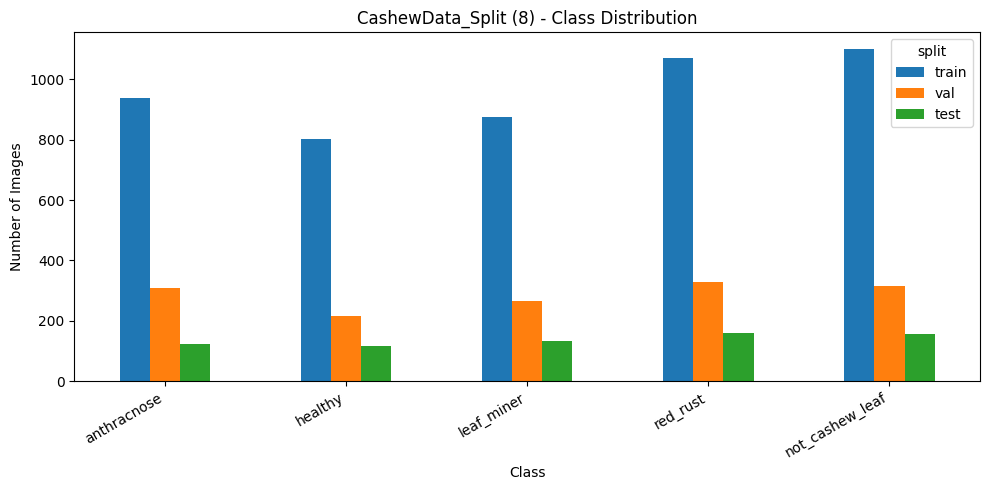

In [ ]:

# ============================================================
# 07. DATASET DISTRIBUTION
# ============================================================

ax = stats_df[["train", "val", "test"]].plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("CashewData_Split (8) - Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Images")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    AGGREGATE_DIR / "class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# ============================================================
# 08. FIXED FILE LISTS + TF.DATA
# ============================================================

CLASS_NAMES = EXPECTED_CLASSES
NUM_CLASSES = len(CLASS_NAMES)
AUTOTUNE = tf.data.AUTOTUNE


def split_arrays(split_name):
    df = (
        valid_df[valid_df["split"] == split_name]
        .copy()
        .reset_index(drop=True)
    )

    return (
        df["path"].to_numpy(),
        df["label"].to_numpy(dtype=np.int32),
        df
    )


train_paths, train_labels, train_meta = split_arrays("train")
val_paths, val_labels, val_meta = split_arrays("val")
test_paths, test_labels, test_meta = split_arrays("test")


def decode_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    return tf.cast(image, tf.float32), label


def make_dataset(paths, labels, seed, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=seed,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        decode_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    ds = ds.prefetch(AUTOTUNE)

    return ds


print("Fixed split:")
print("Train :", len(train_paths))
print("Val   :", len(val_paths))
print("Test  :", len(test_paths))

print("\nClass mapping:")
for idx, class_name in enumerate(CLASS_NAMES):
    print(f"{idx}: {class_name}")


Fixed split:
Train : 4790
Val   : 1430
Test  : 686

Class mapping:
0: anthracnose
1: healthy
2: leaf_miner
3: red_rust
4: not_cashew_leaf


## Model and smoke checks

Raw RGB pixels (0–255) enter the model. Augmentation happens only during
training. Internal ImageNet normalization matches EXP-013 and is checked
against Keras DenseNet preprocessing before training. The smoke check uses
one Train batch and one Validation batch; it never reads Test or holdout.


In [ ]:
# 08. ImageNet backbone, frozen BN, and smoke test
import tempfile
from PIL import ImageOps

AUGMENTATION_CONFIG = {"horizontal_flip": True, "rotation_factor": 0.08,
                       "zoom_factor": 0.10, "contrast_factor": 0.10,
                       "brightness": False}

def densenet_preprocessing(inputs):
    x = layers.Rescaling(1.0 / 255.0, name="densenet_rescale")(inputs)
    return layers.Normalization(mean=[0.485, 0.456, 0.406],
                                variance=[0.229**2, 0.224**2, 0.225**2],
                                axis=-1, name="densenet_preprocess")(x)

def build_transfer_model(seed, weights="imagenet"):
    set_global_seed(seed)
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="raw_rgb")
    augmented = keras.Sequential([
        layers.RandomFlip("horizontal", seed=seed),
        layers.RandomRotation(0.08, seed=seed),
        layers.RandomZoom(0.10, seed=seed),
        layers.RandomContrast(0.10, seed=seed),
    ], name=f"train_only_augmentation_seed_{seed}")(inputs)
    x = densenet_preprocessing(augmented)
    backbone = keras.applications.DenseNet121(include_top=False, weights=weights,
                                               input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    backbone.trainable = False
    features = backbone(x, training=False)  # Keep BN moving statistics fixed in both stages.
    x = layers.Dropout(HEAD_DROPOUT, seed=seed)(features)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32",
                           name="disease_output")(x)
    return keras.Model(inputs, outputs, name=f"DenseNet121_Transfer_seed_{seed}"), backbone

def set_backbone_stage(backbone, stage):
    if stage == "stage1":
        backbone.trainable = False
    elif stage == "stage2":
        backbone.trainable = True
        for layer in backbone.layers:
            layer.trainable = (layer.name.startswith("conv5_") and
                               not isinstance(layer, layers.BatchNormalization))
        if not any(layer.trainable and layer.weights for layer in backbone.layers):
            raise RuntimeError("No weighted conv5_* layer was unfrozen")
        if any(layer.trainable for layer in backbone.layers
               if isinstance(layer, layers.BatchNormalization)):
            raise RuntimeError("A backbone BatchNorm layer is trainable")
    else:
        raise ValueError(stage)
    return int(sum(np.prod(v.shape) for v in backbone.trainable_weights))

def compile_stage(model, lr):
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr,
                                                  weight_decay=WEIGHT_DECAY),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=["accuracy"], steps_per_execution=1, jit_compile=False)

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

if RUN_PIPELINE_SMOKE:
    # enable_op_determinism() requires a global seed before any random op.
    set_global_seed(SEEDS[0])
    parity_input = tf.random.uniform((2, IMG_SIZE, IMG_SIZE, 3), 0, 255, dtype=tf.float32)
    parity_model = keras.Model((p := keras.Input((IMG_SIZE, IMG_SIZE, 3))),
                               densenet_preprocessing(p))
    parity_error = float(tf.reduce_max(tf.abs(
        parity_model(parity_input) - keras.applications.densenet.preprocess_input(parity_input)
    )).numpy())
    if parity_error >= 1e-5:
        raise AssertionError(f"DenseNet preprocessing parity failed: {parity_error}")
    smoke_train = next(iter(make_dataset(train_paths, train_labels, SEEDS[0], training=True)))
    smoke_val = next(iter(make_dataset(val_paths, val_labels, SEEDS[0], training=False)))
    model, backbone = build_transfer_model(SEEDS[0], weights="imagenet")
    initial_backbone = [w.numpy().copy() for w in backbone.weights[:2]]
    stage1_params = set_backbone_stage(backbone, "stage1")
    if stage1_params != 0 or not model.trainable_weights:
        raise AssertionError("Stage 1 trainability is wrong")
    compile_stage(model, STAGE1_LR)
    model.train_on_batch(*smoke_train)
    if any(not np.array_equal(a, w.numpy()) for a, w in zip(initial_backbone, backbone.weights[:2])):
        raise AssertionError("Frozen backbone changed in Stage 1")
    stage1_prob = model(smoke_val[0][:2], training=False).numpy()
    if stage1_prob.shape != (2, NUM_CLASSES) or not np.isfinite(stage1_prob).all():
        raise AssertionError("Invalid model output")
    if not np.allclose(stage1_prob,
                       model(smoke_val[0][:2], training=False).numpy(), atol=1e-6):
        raise AssertionError("Validation/inference path is stochastic")
    if not np.allclose(stage1_prob.sum(axis=1), 1.0, atol=1e-5):
        raise AssertionError("Softmax probabilities do not sum to one")
    bn_layers = [layer for layer in backbone.layers if isinstance(layer, layers.BatchNormalization)]
    bn_means = [layer.moving_mean.numpy().copy() for layer in bn_layers]
    stage2_params = set_backbone_stage(backbone, "stage2")
    if stage2_params <= 0 or stage2_params >= backbone.count_params():
        raise AssertionError("Stage 2 trainable parameter count is implausible")
    old_optimizer = model.optimizer
    compile_stage(model, STAGE2_LR)
    if model.optimizer is old_optimizer:
        raise AssertionError("Stage 2 reused the Stage 1 optimizer")
    model.train_on_batch(*smoke_train)
    if any(not np.array_equal(before, layer.moving_mean.numpy())
           for before, layer in zip(bn_means, bn_layers)):
        raise AssertionError("Backbone BatchNorm moving means changed")
    with tempfile.TemporaryDirectory() as temporary:
        weights_path = Path(temporary) / "smoke.weights.h5"
        model_path = Path(temporary) / "smoke.keras"
        expected = model(smoke_val[0][:2], training=False).numpy()
        model.save_weights(weights_path)
        model.save(model_path)
        head_bias = model.layers[-1].bias
        head_bias.assign_add(tf.one_hot(0, NUM_CLASSES, on_value=20.0,
                                        off_value=0.0, dtype=head_bias.dtype))
        if np.allclose(expected, model(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
            raise AssertionError("Smoke mutation did not change predictions")
        model.load_weights(weights_path)
        if not np.allclose(expected, model(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
            raise AssertionError("Saved weights did not restore predictions")
        restored = keras.models.load_model(model_path, compile=False)
        if not np.allclose(expected, restored(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
            raise AssertionError("Saved .keras model changed predictions")
    save_json(OUT_DIR / "pipeline_smoke.json", {
        "status": "PASS", "preprocess_max_abs_error": parity_error,
        "stage1_backbone_trainable_params": stage1_params,
        "stage2_backbone_trainable_params": stage2_params,
        "backbone_batchnorm_layers": len(bn_layers),
        "weights_and_model_reload": "PASS", "imagenet_initialization": "PASS",
    })
    print("Pipeline smoke PASS: ImageNet, preprocessing, trainability, BN, reload")
    del model, backbone, restored
    keras.backend.clear_session(); gc.collect()
else:
    print("Pipeline smoke NOT_EXECUTED")


Global seed set to: 42
Global seed set to: 42
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Pipeline smoke PASS: ImageNet, preprocessing, trainability, BN, reload


## Freeze the recipe, then train both stages

The configuration and dataset fingerprint are written before fitting. Each
seed has separate Stage 1 and Stage 2 histories and checkpoints. Stage 2
starts from the best Stage 1 weights, uses a fresh optimizer, and keeps
BatchNorm frozen. The selected seed checkpoint comes from Validation only.


In [ ]:
# 09. Immutable experiment recipe
experiment_config = {
    "experiment_id": EXPERIMENT_ID, "notebook_version": NOTEBOOK_VERSION,
    "baseline_source": "EXP-DENSENET121-SCRATCH-5SEEDS-013 source notebook",
    "comparison_scope": "method comparison; ImageNet + two stages versus scratch",
    "dataset": {"name": DATASET_VERSION, "archive": DATASET_ARCHIVE_NAME,
                "archive_sha256": DATASET_ZIP_SHA256,
                "manifest_sha256": DATASET_MANIFEST_SHA256,
                "counts": EXPECTED_TOTALS, "class_names": EXPECTED_CLASSES,
                "real_filename_counts": EXPECTED_REAL_FILENAME_COUNTS},
    "seeds": SEEDS, "input": "raw RGB float32 0..255, bilinear resize 224x224",
    "model": {"backbone": "DenseNet121", "weights": "imagenet",
              "include_top": False, "pooling": "avg", "head_dropout": HEAD_DROPOUT,
              "preprocessing": "inside model: /255 then ImageNet mean/std",
              "augmentation": AUGMENTATION_CONFIG,
              "backbone_call": "backbone(x, training=False)"},
    "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE,
    "loss": "SparseCategoricalCrossentropy",
    "stage1": {"lr": STAGE1_LR, "max_epochs": STAGE1_EPOCHS,
               "early_patience": STAGE1_EARLY_PATIENCE,
               "reduce_patience": STAGE1_REDUCE_PATIENCE, "min_lr": STAGE1_MIN_LR,
               "trainable_backbone": "none"},
    "stage2": {"lr": STAGE2_LR, "max_epochs": STAGE2_EPOCHS,
               "early_patience": STAGE2_EARLY_PATIENCE,
               "reduce_patience": STAGE2_REDUCE_PATIENCE, "min_lr": STAGE2_MIN_LR,
               "trainable_backbone": "conv5_* non-BatchNorm only"},
    "selection_rule": "lowest Validation loss, higher Validation macro-F1, Stage 1 on tie",
    "deployment_rule": "lowest Validation loss, higher macro-F1, lower seed on tie",
    "test_protocol": "disabled by default; evaluate only after Validation lock",
    "holdout_protocol": "previously exposed 48-image historical comparison only",
}
config_path = OUT_DIR / "experiment_config.json"
if RUN_FULL_TRAINING:
    smoke_path = OUT_DIR / "pipeline_smoke.json"
    if not smoke_path.is_file() or json.loads(smoke_path.read_text(
            encoding="utf-8")).get("status") != "PASS":
        raise RuntimeError("Pipeline smoke must PASS before five-seed training")
if config_path.exists():
    if json.loads(config_path.read_text(encoding="utf-8")) != experiment_config:
        raise ValueError("Existing EXP-014 recipe differs. Use a new experiment ID for changes.")
else:
    save_json(config_path, experiment_config)
CONFIG_SHA256 = file_sha256(config_path)
print("Frozen recipe SHA256:", CONFIG_SHA256)


Frozen recipe SHA256: fcf1ebc509cd5c4dd54f9ad073e5af02ba5b412f72210dfee47a998c921292b2


In [ ]:
# 10–14. Two-stage five-seed training and Validation-only selection
class EpochAudit(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.rows = []
        self.current_lr = None
    def on_epoch_begin(self, epoch, logs=None):
        self.current_lr = float(self.model.optimizer.learning_rate.numpy())
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.rows.append({"epoch": epoch + 1, "accuracy": float(logs["accuracy"]),
                          "loss": float(logs["loss"]),
                          "val_accuracy": float(logs["val_accuracy"]),
                          "val_loss": float(logs["val_loss"]),
                          "learning_rate": self.current_lr})

def stage_callbacks(stage_dir, early_patience, reduce_patience, min_lr):
    audit = EpochAudit()
    checkpoint = stage_dir / "best.weights.h5"
    callbacks = [
        audit,
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min",
                                        save_best_only=True, save_weights_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=early_patience,
                                      restore_best_weights=False, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=LR_REDUCTION_FACTOR,
                                          patience=reduce_patience, min_lr=min_lr, verbose=1),
        keras.callbacks.CSVLogger(str(stage_dir / "training_log.csv")),
        keras.callbacks.TerminateOnNaN(),
    ]
    return audit, callbacks, checkpoint

def evaluate_candidate(model, val_ds, stage_dir, stage, audit, elapsed, trainable_params):
    history = pd.DataFrame(audit.rows)
    if history.empty or not np.isfinite(history[["loss", "val_loss"]].to_numpy()).all():
        raise RuntimeError(f"Invalid {stage} history")
    history.to_csv(stage_dir / "history.csv", index=False)
    best = history.sort_values(["val_loss", "epoch"], ascending=[True, True]).iloc[0]
    checkpoint = stage_dir / "best.weights.h5"
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    model.load_weights(checkpoint)
    val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    predicted = probabilities.argmax(axis=1)
    candidate = {
        "stage": stage, "best_epoch": int(best["epoch"]),
        "actual_epochs": len(history), "fit_seconds": float(elapsed),
        "val_loss": float(val_loss), "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(f1_score(val_labels, predicted, labels=np.arange(NUM_CLASSES),
                                        average="macro", zero_division=0)),
        "checkpoint_path": str(checkpoint), "checkpoint_sha256": file_sha256(checkpoint),
        "checkpoint_size_mb": checkpoint.stat().st_size / (1024 ** 2),
        "backbone_trainable_params": trainable_params,
        "learning_rate_first": float(history.iloc[0]["learning_rate"]),
        "learning_rate_last": float(history.iloc[-1]["learning_rate"]),
    }
    if not np.isclose(candidate["val_loss"], float(best["val_loss"]), atol=1e-5):
        raise RuntimeError(f"Reloaded {stage} checkpoint differs from best val_loss epoch")
    save_json(stage_dir / "summary.json", candidate)
    return candidate

def save_selected_validation(seed, model, val_ds, seed_dir, selected):
    output = seed_dir / "validation"
    output.mkdir(exist_ok=True)
    _ = model.predict(val_ds.take(1), verbose=0)  # Warm up model tracing.
    prediction_started = time.perf_counter()
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    prediction_seconds = time.perf_counter() - prediction_started
    y_true = np.asarray(val_labels, dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    if probabilities.shape != (len(y_true), NUM_CLASSES):
        raise ValueError("Validation predictions are not aligned to the fixed file list")
    metrics = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"],
        "val_loss": selected["val_loss"],
        "val_accuracy": float(accuracy_score(y_true, y_pred)),
        "val_macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "prediction_seconds_including_input_pipeline": float(prediction_seconds),
        "inference_time_ms_per_image": float(1000 * prediction_seconds / len(y_true)),
        "anthracnose_recall": float(recall_score(y_true == CLASS_NAMES.index("anthracnose"),
                                                  y_pred == CLASS_NAMES.index("anthracnose"), zero_division=0)),
        "leaf_miner_recall": float(recall_score(y_true == CLASS_NAMES.index("leaf_miner"),
                                                 y_pred == CLASS_NAMES.index("leaf_miner"), zero_division=0)),
    }
    disease_ids = [CLASS_NAMES.index(name) for name in ("anthracnose", "leaf_miner", "red_rust")]
    disease_mask = np.isin(y_true, disease_ids)
    false_healthy_count = int(np.sum(disease_mask & (y_pred == CLASS_NAMES.index("healthy"))))
    metrics.update(false_healthy_count=false_healthy_count,
                   disease_count=int(disease_mask.sum()),
                   false_healthy_rate=float(false_healthy_count / disease_mask.sum()))
    save_json(output / "metrics.json", metrics)
    pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                       target_names=CLASS_NAMES, output_dict=True,
                                       zero_division=0)).T.to_csv(output / "classification_report.csv")
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    cm_norm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES), normalize="true")
    for matrix, suffix in ((cm, ""), (cm_norm, "_normalized")):
        pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            output / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                  vmax=1 if suffix else max(1, matrix.max()))
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=40, ha="right")
        ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        for row in range(NUM_CLASSES):
            for column in range(NUM_CLASSES):
                ax.text(column, row, f"{matrix[row, column]:.2f}" if suffix else str(int(matrix[row, column])),
                        ha="center", va="center", color="black")
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        fig.tight_layout(); fig.savefig(output / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    predictions = pd.DataFrame({
        "filename": val_meta["path"], "is_real_filename": val_meta["is_real_filename"],
        "true_label": [CLASS_NAMES[i] for i in y_true],
        "predicted_label": [CLASS_NAMES[i] for i in y_pred],
        "confidence": probabilities.max(axis=1), "correct": y_true == y_pred,
    })
    for index, name in enumerate(CLASS_NAMES):
        predictions[f"prob_{name}"] = probabilities[:, index]
    predictions.to_csv(output / "predictions.csv", index=False)
    predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
    return metrics

training_rows, validation_rows = [], []
for run_index, seed in enumerate(SEEDS if RUN_FULL_TRAINING else [], start=1):
    seed_dir = OUT_DIR / f"seed_{seed}"
    stage1_dir, stage2_dir = seed_dir / "stage1", seed_dir / "stage2"
    selected_path = seed_dir / "best.weights.h5"
    summary_path = seed_dir / "training_summary.json"
    validation_path = seed_dir / "validation" / "metrics.json"
    if all(path.is_file() for path in (selected_path, summary_path, validation_path,
                                        stage1_dir / "best.weights.h5", stage2_dir / "best.weights.h5")):
        training_rows.append(json.loads(summary_path.read_text(encoding="utf-8")))
        validation_rows.append(json.loads(validation_path.read_text(encoding="utf-8")))
        print("Reusing completed seed", seed)
        continue
    if seed_dir.exists() and any(seed_dir.rglob("*")):
        raise FileExistsError(f"Partial seed output needs review: {seed_dir}")
    for directory in (stage1_dir, stage2_dir):
        directory.mkdir(parents=True)
    print(f"SEED {run_index}/{len(SEEDS)}: {seed}")
    keras.backend.clear_session(); gc.collect(); set_global_seed(seed)
    train_ds = make_dataset(train_paths, train_labels, seed, training=True)
    val_ds = make_dataset(val_paths, val_labels, seed, training=False)
    model, backbone = build_transfer_model(seed, weights="imagenet")

    stage1_params = set_backbone_stage(backbone, "stage1")
    compile_stage(model, STAGE1_LR)
    audit1, callbacks1, _ = stage_callbacks(stage1_dir, STAGE1_EARLY_PATIENCE,
                                            STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE1_EPOCHS,
              callbacks=callbacks1, verbose=1)
    stage1_seconds = time.perf_counter() - started
    stage1 = evaluate_candidate(model, val_ds, stage1_dir, "stage1", audit1,
                                stage1_seconds, stage1_params)

    # evaluate_candidate restored Stage 1 best. Stage 2 starts from these exact weights.
    stage2_params = set_backbone_stage(backbone, "stage2")
    old_optimizer = model.optimizer
    compile_stage(model, STAGE2_LR)
    if model.optimizer is old_optimizer:
        raise AssertionError("Stage 2 must have a new optimizer")
    audit2, callbacks2, _ = stage_callbacks(stage2_dir, STAGE2_EARLY_PATIENCE,
                                            STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE2_EPOCHS,
              callbacks=callbacks2, verbose=1)
    stage2_seconds = time.perf_counter() - started
    stage2 = evaluate_candidate(model, val_ds, stage2_dir, "stage2", audit2,
                                stage2_seconds, stage2_params)

    selected = min((stage1, stage2),
                   key=lambda row: (row["val_loss"], -row["val_macro_f1"],
                                    0 if row["stage"] == "stage1" else 1))
    set_backbone_stage(backbone, selected["stage"])
    source_checkpoint = stage1_dir if selected["stage"] == "stage1" else stage2_dir
    model.load_weights(source_checkpoint / "best.weights.h5")
    selected_reloaded_loss = float(model.evaluate(val_ds, verbose=0)[0])
    if not np.isclose(selected_reloaded_loss, selected["val_loss"], atol=1e-5):
        raise RuntimeError("Selected stage checkpoint failed reload parity")
    shutil.copyfile(source_checkpoint / "best.weights.h5", selected_path)
    stage_selection = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"], "selection_metric": "val_loss",
        "val_loss": selected["val_loss"], "val_macro_f1": selected["val_macro_f1"],
        "tie_break": "higher val_macro_f1, then Stage 1",
        "checkpoint_sha256": file_sha256(selected_path),
        "model_params": int(model.count_params()),
        "stage_candidates": {"stage1": stage1, "stage2": stage2},
    }
    save_json(seed_dir / "stage_selection.json", stage_selection)
    validation = save_selected_validation(seed, model, val_ds, seed_dir, selected)
    summary = {
        "seed": seed, "selected_stage": selected["stage"],
        "stage1_epochs": stage1["actual_epochs"], "stage2_epochs": stage2["actual_epochs"],
        "stage1_training_seconds": stage1_seconds, "stage2_training_seconds": stage2_seconds,
        "training_time_seconds": stage1_seconds + stage2_seconds,
        "stage1_backbone_trainable_params": stage1_params,
        "stage2_backbone_trainable_params": stage2_params,
        "total_parameters": int(model.count_params()),
        "selected_checkpoint_sha256": stage_selection["checkpoint_sha256"],
        "selected_checkpoint_size_mb": selected_path.stat().st_size / (1024 ** 2),
    }
    save_json(summary_path, summary)
    training_rows.append(summary); validation_rows.append(validation)
    del model, backbone, train_ds, val_ds
    keras.backend.clear_session(); gc.collect()

if RUN_FULL_TRAINING:
    training_summary_df = pd.DataFrame(training_rows)
    validation_results_df = pd.DataFrame(validation_rows)
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise RuntimeError("All five seeds must complete before aggregation")
    training_summary_df.to_csv(AGGREGATE_DIR / "training_summary_5seeds.csv", index=False)
    validation_results_df.to_csv(AGGREGATE_DIR / "validation_results_5seeds.csv", index=False)
else:
    training_summary_df = pd.read_csv(AGGREGATE_DIR / "training_summary_5seeds.csv")
    validation_results_df = pd.read_csv(AGGREGATE_DIR / "validation_results_5seeds.csv")
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise ValueError("Saved five-seed order does not match the protocol")

ranked = validation_results_df.sort_values(["val_loss", "val_macro_f1", "seed"],
                                            ascending=[True, False, True])
deployment_seed = int(ranked.iloc[0]["seed"])
selection_lock = {
    "experiment_id": EXPERIMENT_ID, "config_sha256": CONFIG_SHA256,
    "dataset_sha256": DATASET_ZIP_SHA256,
    "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
    "class_names": CLASS_NAMES, "seeds": SEEDS,
    "selection_rule": experiment_config["selection_rule"],
    "deployment_rule": experiment_config["deployment_rule"],
    "deployment_seed": deployment_seed,
    "validation_sha256": file_sha256(AGGREGATE_DIR / "validation_results_5seeds.csv"),
    "selected_checkpoint_sha256": {
        str(seed): file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5") for seed in SEEDS
    },
}
lock_path = OUT_DIR / "validation_selection_lock.json"
if lock_path.exists():
    previous_lock = json.loads(lock_path.read_text(encoding="utf-8"))
    selection_lock["locked_at"] = previous_lock.get("locked_at")
    if previous_lock != selection_lock:
        raise ValueError("Validation lock changed; do not run Test or holdout")
else:
    selection_lock["locked_at"] = datetime.now().astimezone().isoformat()
    save_json(lock_path, selection_lock)
print("Validation-only deployment seed:", deployment_seed)


SEED 1/5: 42
Global seed set to: 42
Global seed set to: 42
Epoch 1/12
299/300 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3724 - loss: 1.6166
Epoch 1: val_loss improved from None to 0.64831, saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-014/seed_42/stage1/best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-014/seed_42/stage1/best.weights.h5
300/300 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.4877 - loss: 1.2935 - val_accuracy: 0.8217 - val_loss: 0.6483 - learning_rate: 3.0000e-04
Epoch 2/12
296/300 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7265 - loss: 0.7688
Epoch 2: val_loss improved from 0.64831 to 0.40760, saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-014/seed_42/stage1/best.weights.h5

Epoch 2

In [ ]:
# 15–17. Validation tables, real_ subgroup, and five-seed panels
summary_columns = ["val_accuracy", "val_macro_precision", "val_macro_recall",
                   "val_macro_f1", "val_balanced_accuracy", "anthracnose_recall",
                   "leaf_miner_recall", "false_healthy_rate"]
summary_rows = []
for metric in summary_columns:
    values = validation_results_df[metric].astype(float)
    summary_rows.append({"metric": metric, "mean": values.mean(),
                         "std": values.std(ddof=1),
                         "report": f"{100*values.mean():.2f} ± {100*values.std(ddof=1):.2f}%"})
inference_ms = validation_results_df["inference_time_ms_per_image"].astype(float)
summary_rows.append({"metric": "inference_time_ms_per_image",
                     "mean": inference_ms.mean(), "std": inference_ms.std(ddof=1),
                     "report": f"{inference_ms.mean():.2f} ± {inference_ms.std(ddof=1):.2f} ms"})
pd.DataFrame(summary_rows).to_csv(AGGREGATE_DIR / "validation_mean_std_summary.csv", index=False)
training_time_columns = ["stage1_training_seconds", "stage2_training_seconds", "training_time_seconds"]
pd.DataFrame([{"metric": column,
               "mean_seconds": training_summary_df[column].mean(),
               "std_seconds": training_summary_df[column].std(ddof=1),
               "total_seconds": training_summary_df[column].sum()}
              for column in training_time_columns]).to_csv(
    AGGREGATE_DIR / "training_time_mean_std_summary.csv", index=False)

real_rows, per_class_rows = [], []
for seed in SEEDS:
    val_dir = OUT_DIR / f"seed_{seed}" / "validation"
    predictions = pd.read_csv(val_dir / "predictions.csv")
    if len(predictions) != len(val_labels):
        raise RuntimeError(f"Seed {seed} Validation rows changed")
    for group, group_df in (("real_filename", predictions[predictions["is_real_filename"]]),
                            ("other_filename", predictions[~predictions["is_real_filename"]])):
        real_rows.append({"seed": seed, "group": group, "correct": int(group_df["correct"].sum()),
                          "total": len(group_df),
                          "accuracy": float(group_df["correct"].mean())})
    report = pd.read_csv(val_dir / "classification_report.csv", index_col=0)
    for class_name in CLASS_NAMES:
        per_class_rows.append({"seed": seed, "class": class_name,
                               "precision": report.loc[class_name, "precision"],
                               "recall": report.loc[class_name, "recall"],
                               "f1": report.loc[class_name, "f1-score"],
                               "support": report.loc[class_name, "support"]})
real_validation_df = pd.DataFrame(real_rows)
for seed in SEEDS:
    row = real_validation_df[(real_validation_df["seed"] == seed) &
                             (real_validation_df["group"] == "real_filename")].iloc[0]
    if int(row["total"]) != EXPECTED_REAL_FILENAME_COUNTS["val"]:
        raise ValueError("The 35 real_ Validation filenames changed")
real_validation_df.to_csv(AGGREGATE_DIR / "real_validation_by_seed.csv", index=False)
pd.DataFrame(per_class_rows).to_csv(AGGREGATE_DIR / "per_class_validation_by_seed.csv", index=False)
pd.DataFrame(per_class_rows).groupby("class")[["precision", "recall", "f1"]].agg(
    ["mean", "std"]).to_csv(AGGREGATE_DIR / "per_class_validation_mean_std.csv")

histories = {}
for seed in SEEDS:
    histories[seed] = (
        pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage1" / "history.csv"),
        pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage2" / "history.csv"),
    )
fig, axes = plt.subplots(2, len(SEEDS), figsize=(28, 10), sharey="row")
for column, seed in enumerate(SEEDS):
    stage1, stage2 = histories[seed]
    boundary = len(stage1)
    for row, metric in enumerate(("accuracy", "loss")):
        ax = axes[row, column]
        for stage_df, offset, stage_name in ((stage1, 0, "Stage 1"), (stage2, boundary, "Stage 2")):
            epoch = stage_df["epoch"] + offset
            ax.plot(epoch, stage_df[metric], color="#2563eb", alpha=0.75,
                    label=f"{stage_name} Train" if row == 0 else None)
            ax.plot(epoch, stage_df[f"val_{metric}"], color="#ea580c", alpha=0.9,
                    label=f"{stage_name} Validation" if row == 0 else None)
            lr = stage_df["learning_rate"].to_numpy()
            reduced = np.flatnonzero(lr[1:] < lr[:-1]) + 1
            for index in reduced:
                ax.axvline(float(epoch.iloc[index]), color="#16a34a", alpha=0.35, linestyle=":")
        ax.axvline(boundary + 0.5, color="black", linestyle="--", alpha=0.8)
        ax.set_xlabel("Combined epoch"); ax.grid(alpha=0.25)
        if column == 0:
            ax.set_ylabel(metric.title())
    axes[0, column].set_title(f"Seed {seed}")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Stage boundary: dashed; learning-rate reductions: dotted green")
fig.tight_layout()
fig.savefig(PANEL_DIR / "training_curves_5seeds_panel.png", dpi=190, bbox_inches="tight")
plt.close(fig)

for normalized, suffix in ((False, ""), (True, "_normalized")):
    fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
    for column, seed in enumerate(SEEDS):
        matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" /
                             f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
        ax = axes[column]
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                  vmax=1 if normalized else max(1, matrix.max()))
        ax.set_title(f"Seed {seed}")
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
        ax.set_yticks(range(NUM_CLASSES))
        ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
        for row in range(NUM_CLASSES):
            for col in range(NUM_CLASSES):
                ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                        ha="center", va="center", color="black", fontsize=8)
        ax.set_xlabel("Predicted")
    axes[0].set_ylabel("True")
    fig.tight_layout()
    fig.savefig(PANEL_DIR / f"validation_confusion_matrices{suffix}_5seeds_panel.png",
                dpi=190, bbox_inches="tight")
    plt.close(fig)
print("Validation summary:")
display(pd.DataFrame(summary_rows))
print("Validation real_ filename subgroup:")
display(real_validation_df)


Validation summary:


,metric,mean,std,report
0,val_accuracy,0.971049,0.002015,97.10 ± 0.20%
1,val_macro_precision,0.969438,0.001877,96.94 ± 0.19%
2,val_macro_recall,0.969767,0.002261,96.98 ± 0.23%
3,val_macro_f1,0.969579,0.002051,96.96 ± 0.21%
4,val_balanced_accuracy,0.969767,0.002261,96.98 ± 0.23%
5,anthracnose_recall,0.938312,0.003247,93.83 ± 0.32%
6,leaf_miner_recall,0.951515,0.004939,95.15 ± 0.49%
7,false_healthy_rate,0.008889,0.000786,0.89 ± 0.08%
8,inference_time_ms_per_image,0.622885,0.009514,0.62 ± 0.01 ms


Validation real_ filename subgroup:


,seed,group,correct,total,accuracy
0,42,real_filename,27,35,0.771429
1,42,other_filename,1359,1395,0.974194
2,123,real_filename,28,35,0.800000
3,123,other_filename,1363,1395,0.977061
4,2026,real_filename,28,35,0.800000
5,2026,other_filename,1357,1395,0.972760
6,3407,real_filename,28,35,0.800000
7,3407,other_filename,1362,1395,0.976344
8,7777,real_filename,28,35,0.800000
9,7777,other_filename,1363,1395,0.977061


## Optional Final Test

Default `RUN_FINAL_TEST=False`. After all five Validation-selected checkpoints
and the lock are frozen, run again with `RUN_FULL_TRAINING=False` and
`RUN_FINAL_TEST=True`. This is a retrospective comparison because EXP-013 Test
results were already available during EXP-014 design. Test never selects the
stage, seed, learning rate or augmentation.


In [ ]:
# 18. Guarded Final Test
def assert_selection_lock():
    saved = json.loads((OUT_DIR / "validation_selection_lock.json").read_text(encoding="utf-8"))
    if saved != selection_lock or saved["config_sha256"] != file_sha256(config_path):
        raise ValueError("Frozen Validation/config lock changed")
    for seed in SEEDS:
        actual = file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
        if actual != saved["selected_checkpoint_sha256"][str(seed)]:
            raise ValueError(f"Seed {seed} checkpoint changed after Validation lock")
    return saved

def load_selected_model(seed):
    # weights=None is only for reconstructing architecture before immediately
    # restoring the EXP-014 trained checkpoint. Training always uses ImageNet.
    model, backbone = build_transfer_model(seed, weights=None)
    selected = json.loads((OUT_DIR / f"seed_{seed}" / "stage_selection.json").read_text(
        encoding="utf-8"))
    set_backbone_stage(backbone, selected["selected_stage"])
    model.load_weights(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
    return model

if RUN_FINAL_TEST:
    assert_selection_lock()
    test_ds = make_dataset(test_paths, test_labels, SEEDS[0], training=False)
    test_rows = []
    for seed in SEEDS:
        keras.backend.clear_session(); gc.collect()
        model = load_selected_model(seed)
        output = OUT_DIR / f"seed_{seed}" / "test"
        output.mkdir(exist_ok=True)
        _ = model.predict(test_ds.take(1), verbose=0)  # Warm up tracing.
        started = time.perf_counter()
        probability = np.asarray(model.predict(test_ds, verbose=0))
        elapsed = time.perf_counter() - started
        y_true = np.asarray(test_labels, dtype=np.int32)
        y_pred = probability.argmax(axis=1)
        if probability.shape != (len(y_true), NUM_CLASSES):
            raise RuntimeError("Final Test prediction count mismatch")
        test_row = {
            "seed": seed, "images": len(y_true),
            "loss": float(-np.log(np.clip(probability[np.arange(len(y_true)), y_true], 1e-7, 1)).mean()),
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "prediction_seconds_including_input_pipeline": elapsed,
            "inference_time_ms_per_image": 1000 * elapsed / len(y_true),
        }
        for group_name, mask in (("real_filename", test_meta["is_real_filename"].to_numpy(dtype=bool)),
                                 ("other_filename", ~test_meta["is_real_filename"].to_numpy(dtype=bool))):
            test_row[f"{group_name}_correct"] = int((y_true[mask] == y_pred[mask]).sum())
            test_row[f"{group_name}_total"] = int(mask.sum())
            test_row[f"{group_name}_accuracy"] = float(accuracy_score(y_true[mask], y_pred[mask]))
        save_json(output / "metrics.json", test_row)
        pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                           target_names=CLASS_NAMES, output_dict=True,
                                           zero_division=0)).T.to_csv(output / "classification_report.csv")
        predictions = pd.DataFrame({"filename": test_meta["path"],
                                    "is_real_filename": test_meta["is_real_filename"],
                                    "true_label": [CLASS_NAMES[i] for i in y_true],
                                    "predicted_label": [CLASS_NAMES[i] for i in y_pred],
                                    "confidence": probability.max(axis=1),
                                    "correct": y_true == y_pred})
        for index, name in enumerate(CLASS_NAMES):
            predictions[f"prob_{name}"] = probability[:, index]
        predictions.to_csv(output / "predictions.csv", index=False)
        predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
        cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
        for normalized, suffix in ((False, ""), (True, "_normalized")):
            matrix = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                      normalize="true" if normalized else None)
            pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
                output / f"confusion_matrix{suffix}.csv")
        test_rows.append(test_row)
        del model
    test_results_df = pd.DataFrame(test_rows)
    test_results_df.to_csv(AGGREGATE_DIR / "test_results_5seeds.csv", index=False)
    pd.DataFrame([{"metric": col, "mean": test_results_df[col].mean(),
                   "std": test_results_df[col].std(ddof=1)}
                  for col in ("accuracy", "macro_precision", "macro_recall", "macro_f1",
                              "balanced_accuracy", "inference_time_ms_per_image")]).to_csv(
        AGGREGATE_DIR / "test_mean_std_summary.csv", index=False)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "test" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(PANEL_DIR / f"test_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(test_results_df)
else:
    print("Final Test PENDING (RUN_FINAL_TEST=False)")


Final Test PENDING (RUN_FINAL_TEST=False)


## Optional historical real holdout

Default `RUN_REAL_HOLDOUT=False`. The 49-image archive was previously
inspected for EXP-013 and has one exact Test duplicate. The evaluator removes
that duplicate and scores 48 images. Any EXP-014 score on it is labeled
**historical / exposed**, never a fresh blind generalization estimate.


In [ ]:
"""Historical external classification evaluation embedded in EXP-014.

This file has no training code. Holdout labels never select checkpoints or seeds.
"""

import hashlib
import json
import os
import stat
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score


REAL_HOLDOUT_HELPER_VERSION = "006.1"
REAL_HOLDOUT_CMAP = LinearSegmentedColormap.from_list(
    "real_holdout_readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)


def holdout_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest().upper()


def resolve_holdout_archive(archive_name, override=None):
    if override is not None:
        candidate = Path(override)
        if not candidate.is_file():
            raise FileNotFoundError(candidate)
        return candidate
    if Path("/content/drive/MyDrive").is_dir():
        candidate = Path("/content/drive/MyDrive/Cashew_Leaf_model_result/Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if os.name == "nt":
        candidate = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if Path("/kaggle/input").is_dir():
        candidates = sorted(Path("/kaggle/input").rglob(archive_name))
        if len(candidates) == 1:
            return candidates[0]
    raise FileNotFoundError(
        f"Cannot uniquely locate {archive_name}. Set REAL_HOLDOUT_ARCHIVE_OVERRIDE "
        "to the mounted ZIP path; on Colab add the supplied Dataset folder to My Drive."
    )


def prepare_real_holdout(archive_path, extraction_dir, class_names, expected_sha256,
                         expected_counts, reference_rows, audit_dir):
    """Verify the frozen archive, labels, decoding and byte overlap with Split (8).

    reference_rows: dictionaries with path/split and optional existing sha256.
    Exact-byte checking does not establish independence of near-duplicate photos.
    """
    archive_path, extraction_dir, audit_dir = map(Path, (archive_path, extraction_dir, audit_dir))
    actual_hash = holdout_sha256(archive_path)
    if actual_hash != expected_sha256.upper():
        raise ValueError(f"Holdout archive changed: {actual_hash}; expected {expected_sha256}.")
    marker = extraction_dir / ".archive_sha256"
    if extraction_dir.exists():
        if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != actual_hash:
            raise FileExistsError(f"Unverified extraction: {extraction_dir}; choose a new directory.")
    else:
        with zipfile.ZipFile(archive_path) as archive:
            resolved_root = extraction_dir.resolve()
            for member in archive.infolist():
                target = (extraction_dir / member.filename.replace("\\", "/")).resolve()
                is_symlink = stat.S_ISLNK(member.external_attr >> 16)
                if is_symlink or (target != resolved_root and resolved_root not in target.parents):
                    raise ValueError(f"Unsafe ZIP member: {member.filename}")
            extraction_dir.mkdir(parents=True)
            archive.extractall(extraction_dir)
        marker.write_text(actual_hash, encoding="utf-8")

    dataset_root = extraction_dir / "RL_Cashew_holdout"
    if not dataset_root.is_dir():
        raise FileNotFoundError(dataset_root)
    found_classes = sorted(p.name for p in dataset_root.iterdir() if p.is_dir())
    if found_classes != sorted(expected_counts) or not set(found_classes).issubset(class_names):
        raise ValueError(f"Unexpected holdout class folders: {found_classes}")
    rows = []
    for label, name in enumerate(class_names):
        class_dir = dataset_root / name
        files = sorted(p for p in class_dir.rglob("*") if p.is_file()) if class_dir.is_dir() else []
        if len(files) != expected_counts.get(name, 0):
            raise ValueError(f"Unexpected holdout count for {name}: {len(files)}")
        for image_path in files:
            if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                raise ValueError(f"Unsupported holdout image: {image_path}")
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.convert("RGB").load()
            rows.append({"path": str(image_path), "relative_path": image_path.relative_to(dataset_root).as_posix(),
                         "class": name, "label": label, "sha256": holdout_sha256(image_path)})
    manifest = pd.DataFrame(rows)
    if manifest.empty or manifest["sha256"].duplicated().any():
        raise ValueError("Holdout is empty or contains duplicate image bytes.")
    # A marker alone is insufficient: verify cached extraction bytes against the ZIP.
    with zipfile.ZipFile(archive_path) as frozen_archive:
        for row in rows:
            digest = hashlib.sha256()
            with frozen_archive.open("RL_Cashew_holdout/" + row["relative_path"]) as stream:
                for block in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(block)
            if digest.hexdigest().upper() != row["sha256"]:
                raise ValueError(f"Cached holdout extraction changed: {row['relative_path']}")
    audit_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(audit_dir / "archive_dataset_manifest.csv", index=False)

    references = list(reference_rows)
    if not references or not {"train", "val", "test"}.issubset({r["split"] for r in references}):
        raise ValueError("Overlap audit needs the full train/val/test Split (8) reference manifest.")
    holdout_hashes = set(manifest["sha256"])
    holdout_path_by_hash = dict(zip(manifest["sha256"], manifest["relative_path"]))
    overlaps = []
    reference_digest = hashlib.sha256()
    for row in references:
        digest = row.get("sha256") or holdout_sha256(row["path"])
        digest = digest.upper()
        identity = row.get("relative_path", str(row["path"]))
        reference_digest.update(f"{row['split']}\0{identity}\0{digest}\n".encode("utf-8"))
        if digest in holdout_hashes:
            overlaps.append({"reference_path": str(row["path"]), "split": row["split"],
                             "holdout_relative_path": holdout_path_by_hash[digest],
                             "sha256": digest})
    # One known Test duplicate is excluded from scoring, not concealed.
    expected_overlap = {("test", "red_rust/IMG_3244.jpg")}
    observed_overlap = {(row["split"], row["holdout_relative_path"]) for row in overlaps}
    if observed_overlap != expected_overlap:
        raise ValueError(f"Unexpected holdout/Split (8) byte overlaps: {overlaps}")
    evaluated_manifest = manifest[~manifest["sha256"].isin(
        {row["sha256"] for row in overlaps}
    )].reset_index(drop=True)
    evaluated_manifest.to_csv(audit_dir / "dataset_manifest.csv", index=False)
    pd.DataFrame(overlaps).to_csv(audit_dir / "excluded_overlap_images.csv", index=False)
    present = [name for name in class_names if expected_counts.get(name, 0) > 0]
    audit = {"archive_sha256": actual_hash, "archive_name": archive_path.name,
             "archive_manifest_sha256": hashlib.sha256(manifest[["relative_path", "class", "label", "sha256"]]
                  .to_csv(index=False).encode()).hexdigest(),
              "manifest_sha256": hashlib.sha256(evaluated_manifest[["relative_path", "class", "label", "sha256"]]
                 .to_csv(index=False).encode()).hexdigest(),
             "counts": {name: expected_counts.get(name, 0) for name in class_names},
             "images": len(evaluated_manifest), "archive_images": len(manifest),
              "excluded_overlap_images": len(overlaps),
              "evaluated_counts": evaluated_manifest["class"].value_counts().to_dict(),
              "present_classes": present,
             "unsupported_classes": [name for name in class_names if name not in present],
             "reference_images_checked": len(references), "reference_fingerprint": reference_digest.hexdigest(),
             "byte_overlap_count": len(overlaps), "byte_overlaps": overlaps,
             "limitation": "Byte audit only; near-duplicate photos and shared trees/sessions need a separate audit."}
    (audit_dir / "dataset_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
    print("Real holdout:", len(evaluated_manifest), "evaluated of", len(manifest),
          "archive images; excluded exact Test duplicate:", overlaps)
    print("Present classes:", present)
    print("Not evaluated (no true examples):", audit["unsupported_classes"])
    return evaluated_manifest, audit


def save_real_holdout_seed(manifest, probabilities, class_names, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.shape != (len(manifest), len(class_names)) or not np.isfinite(probabilities).all():
        raise ValueError("Holdout predictions have invalid shape or non-finite values.")
    if (probabilities < 0).any() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Holdout evaluator expects probabilities, not logits.")
    y_true = manifest["label"].to_numpy(dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    present_ids = sorted(set(y_true.tolist()))
    all_ids = list(range(len(class_names)))
    result = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision_present_classes": float(precision_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_recall_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_f1_present_classes": float(f1_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "balanced_accuracy_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "images": len(manifest), "macro_class_count": len(present_ids),
    }
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=all_ids,
        target_names=class_names, output_dict=True, zero_division=0)).transpose()
    per_class = report.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
    per_class["evaluated"] = per_class["support"] > 0
    # No evidence for unsupported true classes: don't present placeholder zeros as performance.
    per_class.loc[~per_class["evaluated"], ["precision", "recall", "f1-score"]] = np.nan
    per_class.to_csv(output_dir / "per_class_metrics.csv", index_label="class")
    readable_report = per_class.copy()
    readable_report["scope"] = np.where(readable_report["evaluated"], "true class present", "not evaluated: zero true support")
    readable_report.loc["macro avg (present classes)"] = [
        result["macro_precision_present_classes"], result["macro_recall_present_classes"],
        result["macro_f1_present_classes"], len(manifest), True,
        f"{len(present_ids)} supported true classes only",
    ]
    readable_report.loc["weighted avg"] = [
        report.loc["weighted avg", "precision"], report.loc["weighted avg", "recall"],
        report.loc["weighted avg", "f1-score"], len(manifest), True, "weighted by true support",
    ]
    readable_report.to_csv(output_dir / "classification_report.csv", index_label="class")
    predictions = manifest[["relative_path", "class", "label"]].copy()
    predictions["predicted_label"] = y_pred
    predictions["predicted_class"] = [class_names[i] for i in y_pred]
    predictions["confidence"] = probabilities.max(axis=1)
    predictions["correct"] = y_true == y_pred
    for label, name in enumerate(class_names):
        predictions[f"probability_{name}"] = probabilities[:, label]
    predictions.to_csv(output_dir / "predictions.csv", index=False)
    matrix = confusion_matrix(y_true, y_pred, labels=all_ids)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        values = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1) if normalized else matrix
        pd.DataFrame(values, index=class_names, columns=class_names).to_csv(output_dir / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(9, 8), facecolor="white")
        ax.set_facecolor("white")
        ax.imshow(values, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                  vmax=1 if normalized else max(int(matrix.max()), 1))
        ax.set_xticks(all_ids, class_names, rotation=40, ha="right", color="black")
        ax.set_yticks(all_ids, class_names, color="black")
        ax.set_xlabel("Predicted class", color="black")
        ax.set_ylabel("True class", color="black")
        ax.set_title("Real holdout" + (" (row normalized)" if normalized else ""), color="black")
        for row in all_ids:
            for col in all_ids:
                text = f"{values[row, col]:.2f}" if normalized else str(int(values[row, col]))
                if normalized and row not in present_ids:
                    text = "N/A"
                ax.text(col, row, text, ha="center", va="center", color="black")
        fig.tight_layout()
        fig.savefig(output_dir / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    (output_dir / "metrics.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result


def evaluate_real_holdout(manifest, audit, class_names, seeds, validation_results,
                          checkpoints, load_model, make_dataset, clear_session,
                          output_dir, outputs_are_logits=False):
    """Freeze all checkpoints and validation selection BEFORE any prediction.

    Completed evaluations are read back, not repeated. Interrupted evaluations
    may resume only with the same checkpoint, validation and archive fingerprints.
    """
    output_dir = Path(output_dir)
    seeds = [int(seed) for seed in seeds]
    validation_results = validation_results.copy()
    if validation_results["seed"].tolist() != seeds:
        raise ValueError("Holdout evaluation requires completed, ordered validation for every seed.")
    if not np.isfinite(validation_results[["val_macro_f1", "val_loss"]].to_numpy()).all():
        raise ValueError("Validation selection metrics are incomplete.")
    ranked = validation_results.sort_values(["val_loss", "val_macro_f1", "seed"], ascending=[True, False, True])
    deployment_seed = int(ranked.iloc[0]["seed"])
    checkpoint_hashes = {str(seed): holdout_sha256(checkpoints[seed]) for seed in seeds}
    lock = {"helper_version": REAL_HOLDOUT_HELPER_VERSION, "archive_sha256": audit["archive_sha256"],
            "manifest_sha256": audit["manifest_sha256"],
            "reference_fingerprint": audit["reference_fingerprint"], "seeds": seeds,
            "checkpoint_sha256": checkpoint_hashes, "deployment_seed": deployment_seed,
            # Canonical float precision avoids false lock changes on CSV reload.
            "validation_sha256": hashlib.sha256(validation_results.to_csv(index=False, float_format="%.12g").encode()).hexdigest(),
            "model_classes": class_names, "macro_classes": audit["present_classes"],
            "selection_source": "validation only; lowest val_loss, then macro F1 and seed",
            "outputs_are_logits": outputs_are_logits}
    lock_path = output_dir / "evaluation_lock.json"
    if lock_path.exists():
        if json.loads(lock_path.read_text(encoding="utf-8")) != lock:
            raise ValueError("Holdout lock changed. Do not retune using holdout or overwrite its results.")
    else:
        output_dir.mkdir(parents=True, exist_ok=True)
        lock_path.write_text(json.dumps(lock, indent=2), encoding="utf-8")
    aggregate_dir = output_dir / "aggregate"
    aggregate_dir.mkdir(exist_ok=True)
    results_path = aggregate_dir / "real_holdout_results_5seeds.csv"
    if (output_dir / "evaluation_completed.json").exists():
        print("Real holdout already completed; reading frozen results, not running predictions again.")
        return pd.read_csv(results_path)
    result_rows = []
    for seed in seeds:
        seed_dir = output_dir / f"seed_{seed}"
        completed_path = seed_dir / "evaluation_completed.json"
        if completed_path.exists():
            row = json.loads(completed_path.read_text(encoding="utf-8"))
        else:
            clear_session()
            model = load_model(seed)
            dataset = make_dataset(manifest)
            _ = model.predict(dataset.take(1), verbose=0)  # Warm up tracing.
            start = time.perf_counter()
            scores = np.asarray(model.predict(dataset, verbose=0))
            prediction_seconds = time.perf_counter() - start
            if outputs_are_logits:
                exponentials = np.exp(scores - scores.max(axis=1, keepdims=True))
                scores = exponentials / exponentials.sum(axis=1, keepdims=True)
            row = {"seed": seed, **save_real_holdout_seed(manifest, scores, class_names, seed_dir),
                   "prediction_seconds_including_input_pipeline": prediction_seconds,
                   "inference_time_ms_per_image": 1000.0 * prediction_seconds / len(manifest),
                   "fps_including_input_pipeline": len(manifest) / prediction_seconds}
            completed_path.write_text(json.dumps(row, indent=2), encoding="utf-8")
            del model, scores, dataset
            clear_session()
        result_rows.append(row)
    results = pd.DataFrame(result_rows)
    results.to_csv(results_path, index=False)
    metric_columns = [c for c in results if c not in {"seed", "images", "macro_class_count"}]
    results[metric_columns].agg(["mean", "std"]).transpose().to_csv(aggregate_dir / "real_holdout_mean_std.csv")
    per_class = pd.concat([pd.read_csv(output_dir / f"seed_{seed}" / "per_class_metrics.csv")
                          .assign(seed=seed) for seed in seeds], ignore_index=True)
    per_class.groupby("class")[["precision", "recall", "f1-score"]].agg(["mean", "std"]).to_csv(
        aggregate_dir / "per_class_real_holdout_mean_std.csv")
    deployment_result = next(row for row in result_rows if row["seed"] == deployment_seed)
    (aggregate_dir / "deployment_seed_result.json").write_text(json.dumps({
        "selection_source": "validation only, fixed before holdout", "result": deployment_result,
    }, indent=2), encoding="utf-8")
    (output_dir / "evaluation_completed.json").write_text(json.dumps({
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
        "note": "No model or seed selection on holdout. SD measures training-seed variability, not sampling uncertainty.",
    }, indent=2), encoding="utf-8")
    print("Real holdout results (macro metrics over supported true classes only):")
    print(results)
    return results


# 19. Guarded, exposed real-world comparison
if RUN_REAL_HOLDOUT:
    assert_selection_lock()
    holdout_archive = resolve_holdout_archive(REAL_HOLDOUT_ARCHIVE_NAME,
                                               REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    holdout_reference_rows = valid_df.assign(
        relative_path=valid_df["path"].map(
            lambda path: Path(path).relative_to(DATASET_PATH).as_posix())
    ).to_dict("records")
    if Path("/content").is_dir():
        holdout_extract_dir = Path("/content/real_holdout_014") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    elif Path("/kaggle/working").is_dir():
        holdout_extract_dir = Path("/kaggle/working/real_holdout_014") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    else:
        holdout_extract_dir = Path(tempfile.gettempdir()) / "real_holdout_014" / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    holdout_dir = OUT_DIR / "real_holdout"
    holdout_manifest, holdout_audit = prepare_real_holdout(
        holdout_archive, holdout_extract_dir, CLASS_NAMES,
        REAL_HOLDOUT_ARCHIVE_SHA256, REAL_HOLDOUT_EXPECTED_COUNTS,
        holdout_reference_rows, holdout_dir,
    )
    if len(holdout_manifest) != 48:
        raise ValueError("Historical holdout must have 48 scored images")
    def make_holdout_dataset(manifest):
        dataset = tf.data.Dataset.from_tensor_slices((
            manifest["path"].tolist(), manifest["label"].to_numpy(dtype=np.int32)))
        return dataset.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).batch(
            BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    def clear_holdout_session():
        keras.backend.clear_session(); gc.collect()
    checkpoint_paths = {seed: OUT_DIR / f"seed_{seed}" / "best.weights.h5" for seed in SEEDS}
    holdout_results_df = evaluate_real_holdout(
        holdout_manifest, holdout_audit, CLASS_NAMES, SEEDS, validation_results_df,
        checkpoint_paths, load_selected_model, make_holdout_dataset,
        clear_holdout_session, holdout_dir, outputs_are_logits=False,
    )
    save_json(holdout_dir / "interpretation.json", {
        "status": "HISTORICAL_EXPOSED", "evaluated_images": 48,
        "excluded_exact_test_duplicate": 1,
        "use": "descriptive comparison only; not new blind field validation",
        "selection_source": "Validation only",
    })
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(holdout_dir / f"seed_{seed}" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(holdout_dir / f"holdout_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(holdout_results_df)
else:
    print("Real holdout PENDING (RUN_REAL_HOLDOUT=False; historical exposed set)")


Real holdout PENDING (RUN_REAL_HOLDOUT=False; historical exposed set)


## Export the selected model and inference adapter

The deployment seed was frozen by Validation before either optional
evaluation. The exported `.keras` model accepts raw RGB pixels and contains
the preprocessing layer. The adapter applies EXIF orientation and bilinear
resize, then sends RGB float32 to the model without another normalization.


In [ ]:
# 21. Deployment model, feature models, reusable code
assert_selection_lock()
keras.backend.clear_session(); gc.collect()
deployment_model = load_selected_model(deployment_seed)
deployment_path = MODEL_PACKAGE_DIR / "deployment_model.keras"
deployment_model.save(deployment_path)
reloaded = keras.models.load_model(deployment_path, compile=False)
sample_x = next(iter(make_dataset(val_paths, val_labels, deployment_seed, training=False)))[0][:2]
if not np.allclose(deployment_model(sample_x, training=False).numpy(),
                   reloaded(sample_x, training=False).numpy(), atol=1e-5):
    raise RuntimeError("Deployment .keras reload changed predictions")
trained_backbone = deployment_model.get_layer("densenet121")
feature_input = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
feature_x = densenet_preprocessing(feature_input)
feature_backbone = keras.applications.DenseNet121(include_top=False, weights=None,
                                                  input_shape=(IMG_SIZE, IMG_SIZE, 3))
feature_backbone.set_weights(trained_backbone.get_weights())
feature_map = feature_backbone(feature_x, training=False)
feature_extractor = keras.Model(feature_input, feature_map, name="DenseNet121_feature_extractor")
embedding_model = keras.Model(feature_input, layers.GlobalAveragePooling2D()(feature_map),
                              name="DenseNet121_embedding_model")
feature_extractor.save(MODEL_PACKAGE_DIR / "densenet121_feature_extractor.keras")
embedding_model.save(MODEL_PACKAGE_DIR / "densenet121_embedding_model.keras")
save_json(MODEL_PACKAGE_DIR / "label_map.json",
          {str(index): name for index, name in enumerate(CLASS_NAMES)})
save_json(MODEL_PACKAGE_DIR / "inference_metadata.json", {
    "experiment_id": EXPERIMENT_ID, "deployment_seed": deployment_seed,
    "selection_source": "Validation only", "source_checkpoint_sha256":
        selection_lock["selected_checkpoint_sha256"][str(deployment_seed)],
    "input": "RGB float32 raw 0..255, 224x224, bilinear resize",
    "preprocessing": "contained inside deployment_model.keras",
    "external_divide_by_255": False, "class_names": CLASS_NAMES,
    "historical_holdout_exposed": True,
})

yolo_adapter_code = """from pathlib import Path
import json
import time
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps
from tensorflow import keras

MODEL_DIR = Path("model_package")
classifier = keras.models.load_model(MODEL_DIR / "deployment_model.keras", compile=False)
label_map = json.loads((MODEL_DIR / "label_map.json").read_text(encoding="utf-8"))

def classify_crop(crop):
    started = time.perf_counter()
    if isinstance(crop, np.ndarray):
        crop = Image.fromarray(crop.astype(np.uint8), mode="RGB")
    crop = ImageOps.exif_transpose(crop).convert("RGB")
    rgb = np.asarray(crop, dtype=np.float32)
    resized = tf.image.resize(rgb, [224, 224], method="bilinear").numpy()
    probability = classifier.predict(resized[None, ...], verbose=0)[0]
    class_id = int(np.argmax(probability))
    return {"class_id": class_id, "class_name": label_map[str(class_id)],
            "confidence": float(probability[class_id]),
            "probabilities": probability.tolist(),
            "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}
"""
(CODE_PACKAGE_DIR / "yolo_classifier_adapter.py").write_text(yolo_adapter_code, encoding="utf-8")
continue_code = """from tensorflow import keras
model = keras.models.load_model("model_package/deployment_model.keras", compile=False)
backbone = model.get_layer("densenet121")
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = layer.name.startswith("conv5_") and not isinstance(layer, keras.layers.BatchNormalization)
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-4),
              loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
# Continue only in a NEW experiment ID. Do not overwrite EXP-014 checkpoints.
"""
(CODE_PACKAGE_DIR / "continue_training_example.py").write_text(continue_code, encoding="utf-8")

def predict_field_image(path):
    """Notebook manual inference using the same RGB/EXIF/bilinear adapter path."""
    started = time.perf_counter()
    with Image.open(path) as image:
        rgb = np.asarray(ImageOps.exif_transpose(image).convert("RGB"), dtype=np.float32)
    resized = tf.image.resize(rgb, [IMG_SIZE, IMG_SIZE], method="bilinear").numpy()
    probabilities = reloaded.predict(resized[None, ...], verbose=0)[0]
    predicted = int(np.argmax(probabilities))
    return {"class": CLASS_NAMES[predicted], "confidence": float(probabilities[predicted]),
            "probabilities": probabilities.tolist(),
            "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}

environment = {"python": sys.version, "tensorflow": tf.__version__,
               "keras": getattr(keras, "__version__", "tf.keras"),
               "platform": platform.platform(), "gpu_count": len(gpus),
               "strategy": strategy.__class__.__name__}
save_json(ENV_DIR / "environment.json", environment)
(ENV_DIR / "requirements.txt").write_text(
    f"tensorflow=={tf.__version__}\nnumpy=={np.__version__}\npandas=={pd.__version__}\n"
    "Pillow\nscikit-learn\nmatplotlib\nscipy\n", encoding="utf-8")
print("Deployment seed", deployment_seed, "exported to", deployment_path)


Global seed set to: 123
Deployment seed 123 exported to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-014/model_package/deployment_model.keras


## Report and archive

The FULL ZIP contains both stage checkpoints for all seeds, the selected
deployment model and all reports. The ANALYSIS ZIP contains the notebook,
configuration, figures, predictions and metrics without heavy model files.
Checksums cover the result directory. Exports are created only after actual
five-seed training and a frozen Validation lock.


In [ ]:
# 22–23. README, manifest, FULL/ANALYSIS ZIP, verification
assert_selection_lock()
test_status = "COMPLETED_RETROSPECTIVE" if (AGGREGATE_DIR / "test_results_5seeds.csv").is_file() else "PENDING"
holdout_status = "COMPLETED_HISTORICAL_EXPOSED" if (
    OUT_DIR / "real_holdout" / "evaluation_completed.json").is_file() else "PENDING"
save_json(OUT_DIR / "execution_status.json", {
    "experiment_id": EXPERIMENT_ID, "pipeline_smoke": "PASS" if (
        OUT_DIR / "pipeline_smoke.json").is_file() else "NOT_EXECUTED",
    "five_seed_training": "COMPLETED", "final_test": test_status,
    "real_holdout": holdout_status, "deployment_seed": deployment_seed,
    "dataset_archive_sha256": DATASET_ZIP_SHA256,
    "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
})
readme = f"""# {EXPERIMENT_ID}

DenseNet121 ImageNet transfer learning, five seeds, frozen Split (8) V08.

## Protocol
- Stage 1: frozen backbone, AdamW LR {STAGE1_LR}, up to {STAGE1_EPOCHS} epochs.
- Stage 2: only conv5_* non-BN + head trainable, fresh AdamW LR {STAGE2_LR}, up to {STAGE2_EPOCHS} epochs.
- Dropout {HEAD_DROPOUT}, weight decay {WEIGHT_DECAY}, batch {BATCH_SIZE}.
- Stage checkpoint and deployment seed selected only by Validation loss, macro-F1 tie-break.
- Dataset ZIP SHA256: {DATASET_ZIP_SHA256}.
- Dataset manifest SHA256: {DATASET_MANIFEST_SHA256}.
- EXP-013 comparator: same frozen dataset, class order and augmentation. EXP-013 used scratch weights and one training stage. This is a method comparison, not a pretrained-weight-only ablation.

## Results
- Five-seed training: COMPLETED. Per-stage durations and epochs: `aggregate/training_summary_5seeds.csv`.
- Validation: `aggregate/validation_results_5seeds.csv` and `aggregate/validation_mean_std_summary.csv`.
- Validation inference timing includes input decoding/resizing: `inference_time_ms_per_image` per seed, measured after one-batch warm-up.
- Validation `real_` filename subgroup: `aggregate/real_validation_by_seed.csv` (35 of 1430 images; filename proxy only).
- Anthracnose/leaf miner recall and false-healthy numerator/denominator: `seed_*/validation/metrics.json`.
- Training curves and stage boundaries: `figures/panels/training_curves_5seeds_panel.png`.
- Validation confusion matrices: `figures/panels/validation_confusion_matrices_5seeds_panel.png` and normalized panel.
- Final Test: {test_status}. Earlier EXP-013 Test results make any comparison retrospective.
- Real holdout: {holdout_status}. The 48-image set is previously exposed; it is not a new blind field estimate.
- Deployment seed: {deployment_seed}, chosen before optional final evaluations.

## Model and reuse
- Five selected seed checkpoints: `seed_*/best.weights.h5`.
- Both stage candidates: `seed_*/stage1/best.weights.h5` and `seed_*/stage2/best.weights.h5`.
- Deployment: `model_package/deployment_model.keras`, `densenet121_feature_extractor.keras`, `densenet121_embedding_model.keras`.
- YOLO adapter: `code/yolo_classifier_adapter.py` (RGB, EXIF, bilinear resize; no external normalization).
- Notebook source: `notebook/densenet121_transfer_5seed_014.ipynb`.

## Limits
The historical holdout lacks true `not_cashew_leaf` images; macro metrics cover supported true classes. Seed SD is not a sampling confidence interval. Near-duplicate field photos and shared capture sessions are not ruled out by the exact-byte audit.
"""
(OUT_DIR / "README.md").write_text(readme, encoding="utf-8")
(OUT_DIR / "ARCHIVE_FORMAT.md").write_text(
    "FULL: all stage checkpoints/models/reports. ANALYSIS: text, tables, figures, notebook; no model weights.\n",
    encoding="utf-8")

# Embedded output-free notebook source works even when Colab has no .ipynb on disk.
import base64, zlib
NOTEBOOK_SOURCE_ZLIB_B64 = "..."
notebook_dir = OUT_DIR / "notebook"
notebook_dir.mkdir(exist_ok=True)
notebook_copy = notebook_dir / "densenet121_transfer_5seed_014.ipynb"
notebook_source = json.loads(zlib.decompress(base64.b64decode(NOTEBOOK_SOURCE_ZLIB_B64)))
archive_cell = notebook_source["cells"][24]
template_line = 'NOTEBOOK_SOURCE_ZLIB_B64 = ""'
restored_line = f'NOTEBOOK_SOURCE_ZLIB_B64 = "{NOTEBOOK_SOURCE_ZLIB_B64}"'
if sum(line.startswith(template_line) for line in archive_cell["source"]) != 1:
    raise RuntimeError("Embedded notebook source template changed")
archive_cell["source"] = [line.replace(template_line, restored_line, 1)
                          if line.startswith(template_line) else line
                          for line in archive_cell["source"]]
notebook_copy.write_text(json.dumps(notebook_source, ensure_ascii=False, indent=1) + "\n",
                         encoding="utf-8")

manifest_rows, checksum_lines = [], []
for file_path in sorted(OUT_DIR.rglob("*")):
    if not file_path.is_file() or file_path.name in {"FILE_MANIFEST.csv", "CHECKSUMS.sha256"}:
        continue
    relative = file_path.relative_to(OUT_DIR)
    digest = file_sha256(file_path)
    manifest_rows.append({"path": relative.as_posix(), "size_bytes": file_path.stat().st_size,
                          "sha256": digest})
    checksum_lines.append(f"{digest}  {relative.as_posix()}")
pd.DataFrame(manifest_rows).to_csv(OUT_DIR / "FILE_MANIFEST.csv", index=False)
(OUT_DIR / "CHECKSUMS.sha256").write_text("\n".join(checksum_lines), encoding="utf-8")

full_zip = RESULTS_ROOT / f"{EXPERIMENT_ID}_FULL.zip"
analysis_zip = RESULTS_ROOT / f"{EXPERIMENT_ID}_ANALYSIS.zip"
analysis_suffixes = {".csv", ".json", ".md", ".png", ".txt", ".sha256", ".ipynb", ".py"}
for target, analysis_only in ((full_zip, False), (analysis_zip, True)):
    temp = target.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temp, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        for file_path in OUT_DIR.rglob("*"):
            if not file_path.is_file():
                continue
            relative = file_path.relative_to(OUT_DIR)
            if analysis_only and ("model_package" in relative.parts or
                                  file_path.suffix.lower() not in analysis_suffixes):
                continue
            archive.write(file_path, arcname=Path(EXPERIMENT_ID) / relative)
    with zipfile.ZipFile(temp) as archive:
        names = archive.namelist()
        if (not names or any(not name.startswith(EXPERIMENT_ID + "/") for name in names) or
                f"{EXPERIMENT_ID}/notebook/densenet121_transfer_5seed_014.ipynb" not in names or
                archive.testzip() is not None):
            raise RuntimeError(f"ZIP verification failed: {temp}")
    temp.replace(target)
    print("Verified archive:", target, f"{target.stat().st_size / (1024**2):.2f} MB")


Verified archive: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-014_FULL.zip 587.92 MB
Verified archive: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-014_ANALYSIS.zip 2.19 MB


## Completion check

- Dataset ZIP and canonical manifest must match frozen Split (8).
- Pipeline smoke must pass preprocessing, ImageNet initialization, Stage 1/2
  trainability, BatchNorm state and checkpoint reload before the full run.
- All five seeds need both stage histories, checkpoints and Validation metrics.
- `validation_selection_lock.json` is written before Test or holdout.
- Test and historical holdout remain `PENDING` until their flags are explicitly
  enabled in a later, evaluation-only run.
- No EXP-014 metric is filled in before execution.
